In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [2]:
!pip install -q datasets transformers accelerate evaluate scikit-learn pandas numpy matplotlib seaborn shap

In [3]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
dataset = load_dataset("google/civil_comments")

print(dataset)

README.md:   0%|          | 0.00/7.73k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  194MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  187MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

... (3 outputs left out)

Generating train split:   0%|          | 0/1804874 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/97320 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/97320 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 1804874
    })
    validation: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 97320
    })
    test: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 97320
    })
})


In [5]:
print("Dataset splits:")
print(dataset)

print("\nTraining columns:")
print(dataset["train"].column_names)

print("\nFirst training example:")
print(dataset["train"][0])

Dataset splits:
DatasetDict({
    train: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 1804874
    })
    validation: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 97320
    })
    test: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 97320
    })
})

Training columns:
['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit']

First training example:
{'text': "This is so cool. It's like, 'would you want your mother to read this??' Really great idea, well done!", 'toxicity': 0.0, 'severe_toxicity': 0.0, 'obscene': 0.0, 'threat': 0.0, 'insult': 0.0, 'identity_attack': 0.0, 'sexual_explicit': 0.0}


In [6]:
for split in dataset:
    print(split, ":", len(dataset[split]), "rows")

train : 1804874 rows
validation : 97320 rows
test : 97320 rows


In [7]:
# Randomly select a smaller subset
# Fixed seed ensures reproducibility

small_dataset = DatasetDict({
    "train": dataset["train"]
        .shuffle(seed=42)
        .select(range(20000)),

    "validation": dataset["validation"]
        .shuffle(seed=42)
        .select(range(4000)),

    "test": dataset["test"]
        .shuffle(seed=42)
        .select(range(4000))
})

print(small_dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 20000
    })
    validation: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 4000
    })
    test: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 4000
    })
})


In [8]:
def add_labels(batch):

    labels = [
        1 if score >= 0.5 else 0
        for score in batch["toxicity"]
    ]

    return {"labels": labels}


small_dataset = small_dataset.map(
    add_labels,
    batched=True
)

print(small_dataset["train"][0])

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

{'text': 'Socialists? What the hell does that have to do with climate science? Good grief.', 'toxicity': 0.30000001192092896, 'severe_toxicity': 0.0, 'obscene': 0.30000001192092896, 'threat': 0.0, 'insult': 0.20000000298023224, 'identity_attack': 0.0, 'sexual_explicit': 0.0, 'labels': 0}


In [9]:
columns_to_remove = [
    col for col in small_dataset["train"].column_names
    if col not in ["text", "labels"]
]

small_dataset = small_dataset.remove_columns(
    columns_to_remove
)

print(small_dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'labels'],
        num_rows: 20000
    })
    validation: Dataset({
        features: ['text', 'labels'],
        num_rows: 4000
    })
    test: Dataset({
        features: ['text', 'labels'],
        num_rows: 4000
    })
})


In [10]:
for split_name, split_data in small_dataset.items():

    counts = pd.Series(
        split_data["labels"]
    ).value_counts().sort_index()

    print(f"\n{split_name.upper()}")

    print("Not Toxic (0):", counts.get(0, 0))
    print("Toxic (1):", counts.get(1, 0))


TRAIN
Not Toxic (0): 18387
Toxic (1): 1613

VALIDATION
Not Toxic (0): 3662
Toxic (1): 338

TEST
Not Toxic (0): 3684
Toxic (1): 316


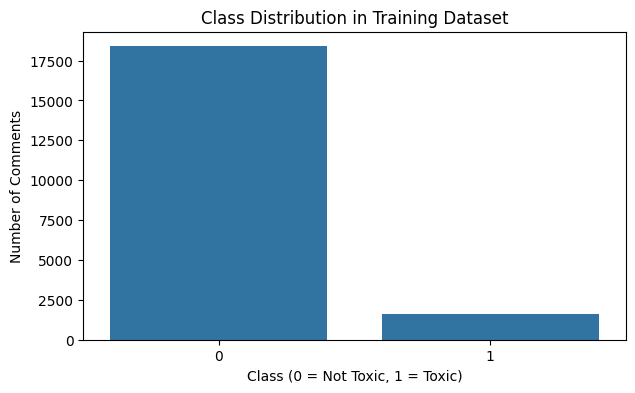

In [11]:
train_labels = pd.Series(
    small_dataset["train"]["labels"]
)

plt.figure(figsize=(7, 4))

sns.countplot(
    x=train_labels
)

plt.title("Class Distribution in Training Dataset")
plt.xlabel("Class (0 = Not Toxic, 1 = Toxic)")
plt.ylabel("Number of Comments")

plt.show()

In [12]:
from transformers import AutoTokenizer

MODEL_NAME = "distilbert/distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer downloaded successfully!")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer downloaded successfully!


In [13]:
sample_text = small_dataset["train"][0]["text"]

tokens = tokenizer.tokenize(sample_text)

token_ids = tokenizer.convert_tokens_to_ids(tokens)

print("Original comment:")
print(sample_text)

print("\nTokens:")
print(tokens)

print("\nToken IDs:")
print(token_ids)

Original comment:
Socialists? What the hell does that have to do with climate science? Good grief.

Tokens:
['socialists', '?', 'what', 'the', 'hell', 'does', 'that', 'have', 'to', 'do', 'with', 'climate', 'science', '?', 'good', 'grief', '.']

Token IDs:
[21633, 1029, 2054, 1996, 3109, 2515, 2008, 2031, 2000, 2079, 2007, 4785, 2671, 1029, 2204, 9940, 1012]


In [14]:
MAX_LENGTH = 128

def tokenize_function(batch):

    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )


tokenized_dataset = small_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

print(tokenized_dataset)

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 20000
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 4000
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 4000
    })
})


In [15]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("Dynamic padding configured successfully!")

Dynamic padding configured successfully!


In [16]:
print("TRAINING DATA")
print(tokenized_dataset["train"][0])

print("\nDataset sizes:")

for split in tokenized_dataset:
    print(split, len(tokenized_dataset[split]))

print("\nInput IDs:")
print(tokenized_dataset["train"][0]["input_ids"][:20])

print("\nAttention mask:")
print(tokenized_dataset["train"][0]["attention_mask"][:20])

print("\nLabel:")
print(tokenized_dataset["train"][0]["labels"])

TRAINING DATA
{'labels': 0, 'input_ids': [101, 21633, 1029, 2054, 1996, 3109, 2515, 2008, 2031, 2000, 2079, 2007, 4785, 2671, 1029, 2204, 9940, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

Dataset sizes:
train 20000
validation 4000
test 4000

Input IDs:
[101, 21633, 1029, 2054, 1996, 3109, 2515, 2008, 2031, 2000, 2079, 2007, 4785, 2671, 1029, 2204, 9940, 1012, 102]

Attention mask:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Label:
0


In [17]:
if "token_type_ids" in tokenized_dataset["train"].column_names:

    tokenized_dataset = tokenized_dataset.remove_columns(
        ["token_type_ids"]
    )

print(tokenized_dataset)

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 20000
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 4000
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 4000
    })
})


In [18]:
import transformers
import torch

print("Transformers version:", transformers.__version__)
print("PyTorch version:", torch.__version__)

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Transformers version: 5.22.0
PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [19]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

print("DistilBERT loaded successfully!")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT loaded successfully!


In [20]:
# Freeze all pretrained DistilBERT parameters

for param in model.distilbert.parameters():
    param.requires_grad = False


# Check trainable and total parameters

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

print(
    "Trainable percentage:",
    round(trainable_params / total_params * 100, 2),
    "%"
)

Total parameters: 66955010
Trainable parameters: 592130
Trainable percentage: 0.88 %


In [21]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),

        "precision": precision_score(
            labels, predictions,
            zero_division=0
        ),

        "recall": recall_score(
            labels, predictions,
            zero_division=0
        ),

        "f1": f1_score(
            labels, predictions,
            zero_division=0
        )
    }

In [22]:
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir="./results/frozen_baseline",

    num_train_epochs=3,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,

    learning_rate=2e-5,

    eval_strategy="epoch",
    logging_strategy="epoch",

    save_strategy="no",

    fp16=torch.cuda.is_available(),

    report_to="none",

    seed=42
)

In [23]:
trainer = Trainer(
    model=model,

    args=training_args,

    train_dataset=tokenized_dataset["train"],

    eval_dataset=tokenized_dataset["validation"],

    data_collator=data_collator,

    compute_metrics=compute_metrics
)

print("Frozen baseline trainer is ready!")

Frozen baseline trainer is ready!


In [24]:
baseline_train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.278488,0.259195,0.915500,0.000000,0.000000,0.000000
2,0.245231,0.244930,0.915500,0.000000,0.000000,0.000000
3,0.237774,0.243260,0.915500,0.000000,0.000000,0.000000


In [25]:
baseline_results = trainer.evaluate(
    tokenized_dataset["test"]
)

print("\nFROZEN DISTILBERT BASELINE RESULTS")

for metric, value in baseline_results.items():

    if isinstance(value, float):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.237774,0.233277,3,0.921000,0.000000,0.000000,0.000000



FROZEN DISTILBERT BASELINE RESULTS
eval_loss: 0.2333
eval_accuracy: 0.9210
eval_precision: 0.0000
eval_recall: 0.0000
eval_f1: 0.0000


In [26]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Predict using validation data only
val_predictions = trainer.predict(
    tokenized_dataset["validation"]
)

val_logits = val_predictions.predictions
val_true = val_predictions.label_ids

val_predicted = np.argmax(val_logits, axis=1)

print("Prediction distribution:")
print(pd.Series(val_predicted).value_counts())

print("\nConfusion Matrix:")
print(confusion_matrix(val_true, val_predicted))

print("\nClassification Report:")
print(
    classification_report(
        val_true,
        val_predicted,
        target_names=["Not Toxic", "Toxic"],
        zero_division=0
    )
)

Prediction distribution:
0    4000
Name: count, dtype: int64

Confusion Matrix:
[[3662    0]
 [ 338    0]]

Classification Report:
              precision    recall  f1-score   support

   Not Toxic       0.92      1.00      0.96      3662
       Toxic       0.00      0.00      0.00       338

    accuracy                           0.92      4000
   macro avg       0.46      0.50      0.48      4000
weighted avg       0.84      0.92      0.88      4000



In [27]:
from collections import Counter

label_counts = Counter(
    small_dataset["train"]["labels"]
)

total = sum(label_counts.values())

class_weights = torch.tensor(
    [
        total / (2 * label_counts[0]),
        total / (2 * label_counts[1])
    ],
    dtype=torch.float
)

print("Class counts:", label_counts)
print("Class weights:", class_weights)

Class counts: Counter({0: 18387, 1: 1613})
Class weights: tensor([0.5439, 6.1996])


In [28]:
from transformers import Trainer
import torch.nn as nn

class WeightedTrainer(Trainer):

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):

        labels = inputs.pop("labels")

        outputs = model(**inputs)

        weights = class_weights.to(
            outputs.logits.device
        )

        loss_function = nn.CrossEntropyLoss(
            weight=weights
        )

        loss = loss_function(
            outputs.logits,
            labels
        )

        return (loss, outputs) if return_outputs else loss

In [29]:
# Load a fresh pretrained model
weighted_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

# Freeze DistilBERT
for param in weighted_model.distilbert.parameters():
    param.requires_grad = False


# Use the same baseline configuration
weighted_args = TrainingArguments(
    output_dir="./results/weighted_frozen",

    num_train_epochs=3,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,

    learning_rate=2e-5,

    eval_strategy="epoch",
    logging_strategy="epoch",

    save_strategy="no",

    fp16=torch.cuda.is_available(),

    report_to="none",

    seed=42
)


# Create weighted trainer
weighted_trainer = WeightedTrainer(
    model=weighted_model,
    args=weighted_args,

    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],

    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Weighted frozen baseline is ready!")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Weighted frozen baseline is ready!


In [30]:
weighted_train_result = weighted_trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.625336,0.577102,0.768250,0.220853,0.689349,0.334530
2,0.548545,0.536487,0.804250,0.239766,0.606509,0.343671
3,0.531026,0.530552,0.815000,0.246851,0.579882,0.346290


In [31]:
weighted_val_results = weighted_trainer.evaluate()

print("\nWEIGHTED FROZEN BASELINE")

for metric, value in weighted_val_results.items():
    if isinstance(value, float):
        print(f"{metric}: {value:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.531026,0.530552,3,0.815000,0.246851,0.579882,0.346290



WEIGHTED FROZEN BASELINE
eval_loss: 0.5306
eval_accuracy: 0.8150
eval_precision: 0.2469
eval_recall: 0.5799
eval_f1: 0.3463


In [32]:
from transformers import set_seed

# Set seed for reproducibility
set_seed(42)

# Load a fresh pretrained DistilBERT
finetuned_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

print("Fresh DistilBERT model loaded!")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Fresh DistilBERT model loaded!


In [33]:
# Allow all parameters to be updated during training

for param in finetuned_model.parameters():
    param.requires_grad = True


# Count parameters

total_params = sum(
    p.numel() for p in finetuned_model.parameters()
)

trainable_params = sum(
    p.numel() for p in finetuned_model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

print(
    "Trainable percentage:",
    round(trainable_params / total_params * 100, 2),
    "%"
)

Total parameters: 66955010
Trainable parameters: 66955010
Trainable percentage: 100.0 %


In [34]:
finetuning_args = TrainingArguments(
    output_dir="./results/full_finetuning",

    num_train_epochs=3,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,

    learning_rate=2e-5,

    eval_strategy="epoch",
    logging_strategy="epoch",

    save_strategy="no",

    fp16=torch.cuda.is_available(),

    report_to="none",

    seed=42
)

In [35]:
finetuned_trainer = WeightedTrainer(
    model=finetuned_model,

    args=finetuning_args,

    train_dataset=tokenized_dataset["train"],

    eval_dataset=tokenized_dataset["validation"],

    data_collator=data_collator,

    compute_metrics=compute_metrics
)

print("Fine-tuning Trainer is ready!")

Fine-tuning Trainer is ready!


In [36]:
finetuning_train_result = finetuned_trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.522428,0.412452,0.932250,0.591781,0.639053,0.614509
2,0.373344,0.534544,0.933500,0.596257,0.659763,0.626404
3,0.219102,0.827463,0.939250,0.642643,0.633136,0.637854


In [37]:
finetuning_val_results = finetuned_trainer.evaluate()

print("\nFULLY FINE-TUNED DISTILBERT RESULTS")

for metric, value in finetuning_val_results.items():

    if isinstance(value, float):
        print(f"{metric}: {value:.4f}")

    else:
        print(f"{metric}: {value}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.219102,0.827463,3,0.939250,0.642643,0.633136,0.637854



FULLY FINE-TUNED DISTILBERT RESULTS
eval_loss: 0.8275
eval_accuracy: 0.9393
eval_precision: 0.6426
eval_recall: 0.6331
eval_f1: 0.6379


In [38]:
comparison = pd.DataFrame([
    {
        "Model": "Unweighted Frozen",
        "Accuracy": 0.9210,
        "Precision": 0.0000,
        "Recall": 0.0000,
        "F1": 0.0000
    },
    {
        "Model": "Weighted Frozen",
        "Accuracy": 0.8150,
        "Precision": 0.246851,
        "Recall": 0.579882,
        "F1": 0.346290
    },
    {
        "Model": "Weighted Fine-tuned",
        "Accuracy": finetuning_val_results["eval_accuracy"],
        "Precision": finetuning_val_results["eval_precision"],
        "Recall": finetuning_val_results["eval_recall"],
        "F1": finetuning_val_results["eval_f1"]
    }
])

print(comparison.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall     F1
  Unweighted Frozen    0.9210     0.0000  0.0000 0.0000
    Weighted Frozen    0.8150     0.2469  0.5799 0.3463
Weighted Fine-tuned    0.9392     0.6426  0.6331 0.6379


In [39]:
from transformers import set_seed
import gc
import os

# Hyperparameter configurations
learning_rates = [1e-5, 2e-5, 3e-5, 5e-5]

tuning_results = []
best_f1 = -1
best_learning_rate = None
best_model_path = None

# Store the results of all experiments
for lr in learning_rates:

    print("\n" + "=" * 55)
    print(f"STARTING EXPERIMENT: Learning Rate = {lr}")
    print("=" * 55)

    # Set seed for reproducibility
    set_seed(42)

    # Load a fresh pretrained model
    tuning_model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2
    )

    # Unfreeze all parameters
    for param in tuning_model.parameters():
        param.requires_grad = True

    # Configure training
    tuning_args = TrainingArguments(

        output_dir=f"./results/tuning_lr_{lr}",

        num_train_epochs=3,

        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,

        learning_rate=lr,

        eval_strategy="epoch",
        logging_strategy="epoch",

        save_strategy="epoch",
        save_total_limit=1,

        load_best_model_at_end=True,
        metric_for_best_model="f1",
        greater_is_better=True,

        fp16=torch.cuda.is_available(),

        report_to="none",

        seed=42
    )

    # Create weighted trainer
    tuning_trainer = WeightedTrainer(

        model=tuning_model,

        args=tuning_args,

        train_dataset=tokenized_dataset["train"],

        eval_dataset=tokenized_dataset["validation"],

        data_collator=data_collator,

        compute_metrics=compute_metrics
    )

    # Train the model
    tuning_trainer.train()

    # Evaluate the best checkpoint
    results = tuning_trainer.evaluate()

    # Record experiment results
    experiment = {
        "Learning Rate": lr,
        "Batch Size": 16,
        "Epochs": 3,
        "Accuracy": results["eval_accuracy"],
        "Precision": results["eval_precision"],
        "Recall": results["eval_recall"],
        "F1": results["eval_f1"],
        "Validation Loss": results["eval_loss"]
    }

    tuning_results.append(experiment)

    print("\nExperiment Results:")
    print(experiment)

    # Save the best model from this configuration
    if results["eval_f1"] > best_f1:

        best_f1 = results["eval_f1"]
        best_learning_rate = lr

        best_model_path = f"./results/best_tuned_model"

        tuning_trainer.save_model(best_model_path)
        tokenizer.save_pretrained(best_model_path)

    # Free GPU memory before next experiment
    del tuning_trainer
    del tuning_model

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


print("\n" + "=" * 55)
print("HYPERPARAMETER TUNING COMPLETED")
print("=" * 55)

print("Best Learning Rate:", best_learning_rate)
print("Best Validation F1:", best_f1)


STARTING EXPERIMENT: Learning Rate = 1e-05


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.519013,0.398683,0.928000,0.558962,0.701183,0.622047
2,0.410017,0.573194,0.939000,0.631285,0.668639,0.649425
3,0.309797,0.669983,0.941250,0.645070,0.677515,0.660895


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (25 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.177353,0.551067,3,0.938500,0.641104,0.618343,0.629518



Experiment Results:
{'Learning Rate': 5e-05, 'Batch Size': 16, 'Epochs': 3, 'Accuracy': 0.9385, 'Precision': 0.6411042944785276, 'Recall': 0.6183431952662722, 'F1': 0.6295180722891566, 'Validation Loss': 0.5510667562484741}

HYPERPARAMETER TUNING COMPLETED
Best Learning Rate: 1e-05
Best Validation F1: 0.6608946608946609


In [40]:
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

print(tuning_df.round(4).to_string(index=False))

 Learning Rate  Batch Size  Epochs  Accuracy  Precision  Recall     F1  Validation Loss
           0.0          16       3    0.9412     0.6451  0.6775 0.6609           0.6700
           0.0          16       3    0.9362     0.6125  0.6686 0.6393           0.5219
           0.0          16       3    0.9392     0.6426  0.6331 0.6379           0.8275
           0.0          16       3    0.9385     0.6411  0.6183 0.6295           0.5511


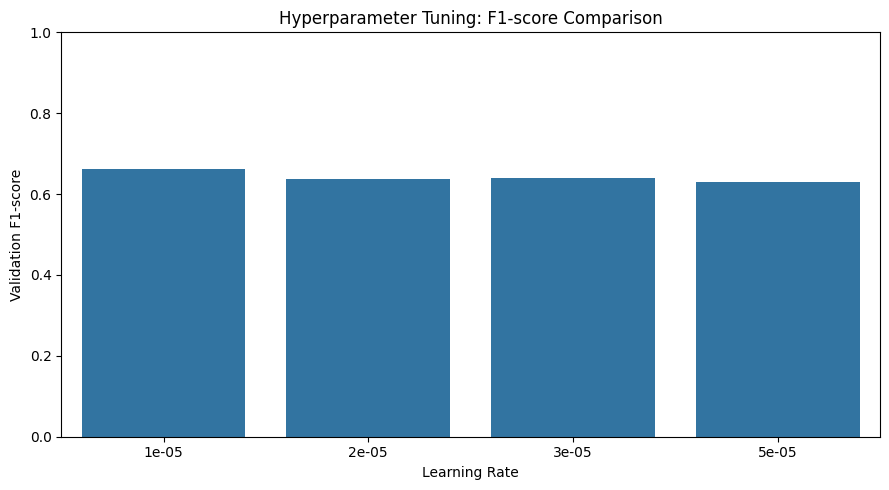

In [41]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=tuning_df,
    x="Learning Rate",
    y="F1"
)

plt.title("Hyperparameter Tuning: F1-score Comparison")
plt.xlabel("Learning Rate")
plt.ylabel("Validation F1-score")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

In [42]:
tuning_df.to_csv(
    "hyperparameter_tuning_results.csv",
    index=False
)

print("Tuning results saved successfully!")

Tuning results saved successfully!


In [43]:
tuning_df = pd.DataFrame(tuning_results)

print(
    tuning_df.to_string(
        index=False,
        formatters={
            "Learning Rate": lambda x: f"{x:.0e}",
            "Accuracy": lambda x: f"{x:.4f}",
            "Precision": lambda x: f"{x:.4f}",
            "Recall": lambda x: f"{x:.4f}",
            "F1": lambda x: f"{x:.4f}",
            "Validation Loss": lambda x: f"{x:.4f}"
        }
    )
)

Learning Rate  Batch Size  Epochs Accuracy Precision Recall     F1 Validation Loss
        1e-05          16       3   0.9413    0.6451 0.6775 0.6609          0.6700
        2e-05          16       3   0.9393    0.6426 0.6331 0.6379          0.8275
        3e-05          16       3   0.9363    0.6125 0.6686 0.6393          0.5219
        5e-05          16       3   0.9385    0.6411 0.6183 0.6295          0.5511


In [44]:
# Load the best tuned model
best_model = AutoModelForSequenceClassification.from_pretrained(
    "./results/best_tuned_model"
)

best_tokenizer = AutoTokenizer.from_pretrained(
    "./results/best_tuned_model"
)

print("Best tuned DistilBERT loaded successfully!")
print("Selected learning rate:", best_learning_rate)
print("Best validation F1:", best_f1)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Best tuned DistilBERT loaded successfully!
Selected learning rate: 1e-05
Best validation F1: 0.6608946608946609


In [45]:
final_test_args = TrainingArguments(
    output_dir="./results/final_test",

    per_device_eval_batch_size=32,

    fp16=torch.cuda.is_available(),

    report_to="none"
)

final_test_trainer = WeightedTrainer(
    model=best_model,

    args=final_test_args,

    eval_dataset=tokenized_dataset["test"],

    data_collator=data_collator,

    compute_metrics=compute_metrics
)

print("Final test evaluator is ready!")

Final test evaluator is ready!


In [46]:
test_output = final_test_trainer.predict(
    tokenized_dataset["test"]
)

print("\nFINAL TEST RESULTS")

for metric, value in test_output.metrics.items():

    if isinstance(value, float):
        print(f"{metric}: {value:.4f}")

    else:
        print(f"{metric}: {value}")


FINAL TEST RESULTS
test_loss: 0.6976
test_model_preparation_time: 0.0071
test_accuracy: 0.9380
test_precision: 0.5977
test_recall: 0.6582
test_f1: 0.6265
test_runtime: 4.7018
test_samples_per_second: 850.7380
test_steps_per_second: 26.5860


Confusion Matrix:
[[3544  140]
 [ 108  208]]

Classification Report:
              precision    recall  f1-score   support

   Not Toxic       0.97      0.96      0.97      3684
       Toxic       0.60      0.66      0.63       316

    accuracy                           0.94      4000
   macro avg       0.78      0.81      0.80      4000
weighted avg       0.94      0.94      0.94      4000



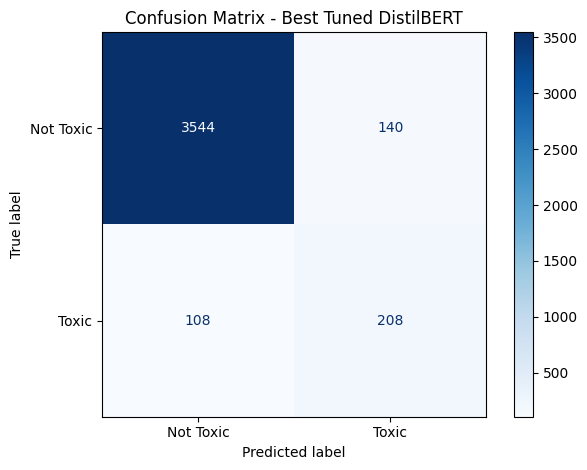

In [47]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import numpy as np
import matplotlib.pyplot as plt

# Actual labels
y_true = test_output.label_ids

# Predicted labels
y_pred = np.argmax(
    test_output.predictions,
    axis=1
)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

# Classification report
print("\nClassification Report:")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Not Toxic", "Toxic"],
        zero_division=0
    )
)

# Visualize
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Toxic", "Toxic"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Best Tuned DistilBERT")

plt.tight_layout()
plt.show()

In [48]:
!pip install -q shap

In [49]:
import shap
import numpy as np
import torch

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [50]:
best_model.eval()

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

best_model = best_model.to(device)

print("Model is ready for SHAP!")

Model is ready for SHAP!


In [51]:
def predict_proba(texts):

    if isinstance(texts, str):
        texts = [texts]

    # Tokenize comments
    inputs = best_tokenizer(
        list(texts),
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    )

    # DistilBERT only needs these inputs
    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
        if key in ["input_ids", "attention_mask"]
    }

    # Predict
    with torch.no_grad():

        outputs = best_model(**inputs)

        probabilities = torch.softmax(
            outputs.logits,
            dim=1
        )

    return probabilities.cpu().numpy()


# Test the prediction function
example = "You are doing a wonderful job!"

print(predict_proba([example]))

[[0.99545276 0.00454726]]


In [52]:
# Original test comments
test_texts = small_dataset["test"]["text"]

# Calculate predicted probabilities
test_probabilities = torch.softmax(
    torch.tensor(test_output.predictions),
    dim=1
).numpy()

# Select examples
categories = {
    "Correct Not Toxic": np.where(
        (y_true == 0) & (y_pred == 0)
    )[0],

    "Correct Toxic": np.where(
        (y_true == 1) & (y_pred == 1)
    )[0],

    "False Positive": np.where(
        (y_true == 0) & (y_pred == 1)
    )[0],

    "False Negative": np.where(
        (y_true == 1) & (y_pred == 0)
    )[0]
}

selected_indices = []

for category, indices in categories.items():

    if len(indices) == 0:
        print("No examples found:", category)
        continue

    # Select the most confident prediction in this category
    predicted_classes = y_pred[indices]

    confidences = test_probabilities[
        indices,
        predicted_classes
    ]

    selected_index = indices[np.argmax(confidences)]

    selected_indices.append(selected_index)

    print("\nCategory:", category)
    print("Comment:", test_texts[selected_index])
    print("Actual label:", y_true[selected_index])
    print("Predicted label:", y_pred[selected_index])
    print(
        "Confidence:",
        round(
            float(test_probabilities[selected_index, y_pred[selected_index]]),
            4
        )
    )


Category: Correct Not Toxic
Comment: I'll stick to this subject. Tax returns can be amended, and apparently this paperwork can too.
Actual label: 0
Predicted label: 0
Confidence: 0.9982

Category: Correct Toxic
Comment: Halfway? This little inbred moron has been a boil on the butt of humanity with his constant threats to his close neighbors and kidnapping foriegn idiot visitors for more money for 5 yrs. Why does China allow this? To keep causing provacation?To keep west paying billions to babysit an idiot? China needs to either mash that pimpel or remove him for good and let N. Koreans pick a leader who will help all its people not just those old buffoons in lock step for aid and perk payouts while most are starving. The West dont want that lousy place, China knows that.  No more money or aid. Maybe NK people will rise up and take him out. He will kill them anyway with his warlord mentality.
Actual label: 1
Predicted label: 1
Confidence: 0.9974

Category: False Positive
Comment: Waste

In [53]:
# Create text masker
text_masker = shap.maskers.Text(best_tokenizer)

# Create SHAP explainer
explainer = shap.Explainer(
    predict_proba,
    text_masker,
    output_names=["Not Toxic", "Toxic"]
)

print("SHAP explainer created successfully!")

SHAP explainer created successfully!


In [54]:
# Collect selected comments
selected_texts = [
    test_texts[i]
    for i in selected_indices
]

# Calculate SHAP values
shap_values = explainer(
    selected_texts,
    max_evals=100,
    batch_size=16
)

print("SHAP explanations generated!")

SHAP explanations generated!


In [55]:
for i, idx in enumerate(selected_indices):

    print("\n" + "=" * 60)

    print("Example:", i + 1)

    print("Comment:", test_texts[idx])

    print(
        "Actual:",
        "Toxic" if y_true[idx] == 1 else "Not Toxic"
    )

    print(
        "Predicted:",
        "Toxic" if y_pred[idx] == 1 else "Not Toxic"
    )

    print("=" * 60)

    # Explain the Toxic class
    shap.plots.text(
        shap_values[i, :, 1]
    )


Example: 1
Comment: I'll stick to this subject. Tax returns can be amended, and apparently this paperwork can too.
Actual: Not Toxic
Predicted: Not Toxic



Example: 2
Comment: Halfway? This little inbred moron has been a boil on the butt of humanity with his constant threats to his close neighbors and kidnapping foriegn idiot visitors for more money for 5 yrs. Why does China allow this? To keep causing provacation?To keep west paying billions to babysit an idiot? China needs to either mash that pimpel or remove him for good and let N. Koreans pick a leader who will help all its people not just those old buffoons in lock step for aid and perk payouts while most are starving. The West dont want that lousy place, China knows that.  No more money or aid. Maybe NK people will rise up and take him out. He will kill them anyway with his warlord mentality.
Actual: Toxic
Predicted: Toxic



Example: 3
Comment: Wasteful spenders tend to be republicans.  GW Bush lefft us with a trillion plus deficit.  The Donald is proposing a stupid wall which will do nothing.  We shall see if the Donald reduces the deficit or be like past republicans and drastically increase it by their proactice of Voodoo.
Actual: Not Toxic
Predicted: Toxic



Example: 4
Comment: My comments keep disappearing because they are 'below the civility guideline".

This is what I wrote:
"Do you ever have your comments simply disappear? Mine wasn't flagged as being uncivil (I always try to be respectful) - the comment showed up initially, but is not here any more."

WTF?
Actual: Toxic
Predicted: Not Toxic


In [56]:
# Real-world comments selected for testing

real_world_comments = [
    "I appreciate the effort you put into this. Thank you!",

    "Your explanation is clear and very helpful.",

    "You are an idiot and your ideas are completely worthless.",

    "Nobody asked for your stupid opinion.",

    "I strongly disagree with your argument, but I respect your opinion.",

    "This is one of the worst explanations I have ever read."
]

# Human-assessed reference labels
# 0 = Not Toxic
# 1 = Toxic

expected_labels = [
    0,
    0,
    1,
    1,
    0,
    0
]

print("Number of real-world comments:", len(real_world_comments))

Number of real-world comments: 6


In [57]:
# Get prediction probabilities

real_world_probabilities = predict_proba(
    real_world_comments
)

# Get predicted classes

real_world_predictions = np.argmax(
    real_world_probabilities,
    axis=1
)

print("Predictions generated successfully!")

Predictions generated successfully!


In [58]:
import pandas as pd

results = []

for i, comment in enumerate(real_world_comments):

    predicted_label = real_world_predictions[i]

    confidence = real_world_probabilities[
        i, predicted_label
    ]

    results.append({
        "Comment": comment,

        "Expected Class": (
            "Toxic" if expected_labels[i] == 1
            else "Not Toxic"
        ),

        "Predicted Class": (
            "Toxic" if predicted_label == 1
            else "Not Toxic"
        ),

        "Toxic Probability": round(
            float(real_world_probabilities[i, 1]), 4
        ),

        "Confidence": round(
            float(confidence), 4
        ),

        "Human Check": (
            "Matches"
            if predicted_label == expected_labels[i]
            else "Does not match"
        )
    })

real_world_results = pd.DataFrame(results)

pd.set_option("display.max_colwidth", None)

display(real_world_results)

,Comment,Expected Class,Predicted Class,Toxic Probability,Confidence,Human Check
0,I appreciate the effort you put into this. Thank you!,Not Toxic,Not Toxic,0.0029,0.9971,Matches
1,Your explanation is clear and very helpful.,Not Toxic,Not Toxic,0.0024,0.9976,Matches
2,You are an idiot and your ideas are completely worthless.,Toxic,Toxic,0.9967,0.9967,Matches
3,Nobody asked for your stupid opinion.,Toxic,Toxic,0.9963,0.9963,Matches
4,"I strongly disagree with your argument, but I respect your opinion.",Not Toxic,Not Toxic,0.0026,0.9974,Matches
5,This is one of the worst explanations I have ever read.,Not Toxic,Not Toxic,0.0044,0.9956,Matches


In [59]:
from sklearn.metrics import accuracy_score

real_world_accuracy = accuracy_score(
    expected_labels,
    real_world_predictions
)

print(
    "Agreement with human-assessed labels:",
    f"{real_world_accuracy * 100:.2f}%"
)

Agreement with human-assessed labels: 100.00%


In [60]:
real_world_results.to_csv(
    "real_world_testing_results.csv",
    index=False
)

print("Real-world testing results saved!")

Real-world testing results saved!


In [61]:
# Save SHAP explanations as an HTML report

shap_html = shap.plots.text(
    shap_values,
    display=False
)

with open(
    "shap_explanations.html",
    "w",
    encoding="utf-8"
) as f:

    f.write(shap_html.data)

print("SHAP explanation report saved!")

AttributeError: 'str' object has no attribute 'data'

In [62]:
for i in range(len(selected_texts)):

    shap_html = shap.plots.text(
        shap_values[i, :, 1],
        display=False
    )

    with open(
        f"shap_example_{i+1}.html",
        "w",
        encoding="utf-8"
    ) as f:

        f.write(shap_html.data)

print("Individual SHAP reports saved!")

AttributeError: 'str' object has no attribute 'data'

In [63]:
import shap

# Generate HTML for all explanations
shap_html = shap.plots.text(
    shap_values,
    display=False
)

# Save directly because the result is already a string
with open(
    "shap_explanations.html",
    "w",
    encoding="utf-8"
) as f:

    f.write(shap_html)

print("All SHAP explanations saved successfully!")

All SHAP explanations saved successfully!


In [64]:
for i in range(len(selected_texts)):

    shap_html = shap.plots.text(
        shap_values[i, :, 1],
        display=False
    )

    with open(
        f"shap_example_{i+1}.html",
        "w",
        encoding="utf-8"
    ) as f:

        f.write(shap_html)

    print(f"SHAP Example {i+1} saved!")

print("\nAll individual SHAP reports saved!")

SHAP Example 1 saved!
SHAP Example 2 saved!
SHAP Example 3 saved!
SHAP Example 4 saved!

All individual SHAP reports saved!


In [65]:
import os

print("Saved SHAP files:")

for filename in os.listdir("."):

    if filename.endswith(".html") and "shap" in filename:

        print(filename)

Saved SHAP files:
shap_example_1.html
shap_example_3.html
shap_explanations.html
shap_example_2.html
shap_example_4.html


In [66]:
from google.colab import files

files.download("shap_explanations.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [67]:
def predict_toxic_probability(texts):

    probabilities = predict_proba(texts)

    # Return only Toxic class probability (class 1)
    return probabilities[:, 1]


# Test the function
test_comment = [
    "You are an idiot and your ideas are worthless."
]

print(
    "Toxic probability:",
    predict_toxic_probability(test_comment)
)

Toxic probability: [0.9967649]


In [68]:
toxic_explainer = shap.Explainer(
    predict_toxic_probability,
    shap.maskers.Text(best_tokenizer),
    output_names=["Toxic probability"]
)

print("Toxic-class SHAP explainer created!")

Toxic-class SHAP explainer created!


In [69]:
toxic_shap_values = toxic_explainer(
    selected_texts,
    max_evals=100,
    batch_size=16
)

print("Toxic-class SHAP values generated!")

AssertionError: You have passed a list for output_names but the model seems to not have multiple outputs!

In [70]:
toxic_explainer = shap.Explainer(
    predict_toxic_probability,
    shap.maskers.Text(best_tokenizer)
)

print("Toxic-class SHAP explainer created successfully!")

Toxic-class SHAP explainer created successfully!


In [71]:
toxic_shap_values = toxic_explainer(
    selected_texts,
    max_evals=100,
    batch_size=16
)

print("Toxic-class SHAP values generated successfully!")

Toxic-class SHAP values generated successfully!


In [72]:
for i, idx in enumerate(selected_indices):

    print("\n" + "=" * 60)

    print("Example:", i + 1)

    print("Comment:", test_texts[idx])

    print(
        "Actual:",
        "Toxic" if y_true[idx] == 1 else "Not Toxic"
    )

    print(
        "Predicted:",
        "Toxic" if y_pred[idx] == 1 else "Not Toxic"
    )

    print(
        "Toxic Probability:",
        round(float(test_probabilities[idx, 1]), 4)
    )

    print("=" * 60)

    shap.plots.text(toxic_shap_values[i])


Example: 1
Comment: I'll stick to this subject. Tax returns can be amended, and apparently this paperwork can too.
Actual: Not Toxic
Predicted: Not Toxic
Toxic Probability: 0.0018



Example: 2
Comment: Halfway? This little inbred moron has been a boil on the butt of humanity with his constant threats to his close neighbors and kidnapping foriegn idiot visitors for more money for 5 yrs. Why does China allow this? To keep causing provacation?To keep west paying billions to babysit an idiot? China needs to either mash that pimpel or remove him for good and let N. Koreans pick a leader who will help all its people not just those old buffoons in lock step for aid and perk payouts while most are starving. The West dont want that lousy place, China knows that.  No more money or aid. Maybe NK people will rise up and take him out. He will kill them anyway with his warlord mentality.
Actual: Toxic
Predicted: Toxic
Toxic Probability: 0.9974



Example: 3
Comment: Wasteful spenders tend to be republicans.  GW Bush lefft us with a trillion plus deficit.  The Donald is proposing a stupid wall which will do nothing.  We shall see if the Donald reduces the deficit or be like past republicans and drastically increase it by their proactice of Voodoo.
Actual: Not Toxic
Predicted: Toxic
Toxic Probability: 0.9972



Example: 4
Comment: My comments keep disappearing because they are 'below the civility guideline".

This is what I wrote:
"Do you ever have your comments simply disappear? Mine wasn't flagged as being uncivil (I always try to be respectful) - the comment showed up initially, but is not here any more."

WTF?
Actual: Toxic
Predicted: Not Toxic
Toxic Probability: 0.0023


In [73]:
for i in range(len(selected_texts)):

    shap_html = shap.plots.text(
        toxic_shap_values[i],
        display=False
    )

    with open(
        f"toxic_shap_example_{i+1}.html",
        "w",
        encoding="utf-8"
    ) as f:

        f.write(shap_html)

print("All four Toxic-class SHAP explanations saved!")

All four Toxic-class SHAP explanations saved!


In [74]:
import os

os.makedirs("shap_explanations", exist_ok=True)

for i, idx in enumerate(selected_indices):

    html_content = shap.plots.text(
        toxic_shap_values[i],
        display=False
    )

    file_path = f"shap_explanations/example_{i+1}.html"

    with open(file_path, "w", encoding="utf-8") as f:
        f.write(html_content)

    print(f"Saved: {file_path}")

Saved: shap_explanations/example_1.html
Saved: shap_explanations/example_2.html
Saved: shap_explanations/example_3.html
Saved: shap_explanations/example_4.html


In [75]:
import shutil
from google.colab import files

shutil.make_archive(
    "shap_explanations",
    "zip",
    "shap_explanations"
)

files.download("shap_explanations.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [76]:
import pandas as pd

comparison_data = {
    "Model": [
        "Frozen DistilBERT (Unweighted)",
        "Frozen DistilBERT (Weighted)",
        "Fine-tuned DistilBERT (Weighted)",
        "Best Tuned DistilBERT",
        "Best Tuned DistilBERT (Test)"
    ],

    "Evaluation Set": [
        "Validation",
        "Validation",
        "Validation",
        "Validation",
        "Test"
    ],

    "Accuracy": [
        0.9210,
        0.8150,
        0.9393,
        0.94125,
        0.9380
    ],

    "Precision": [
        0.0000,
        0.2469,
        0.6426,
        0.6451,
        0.5977
    ],

    "Recall": [
        0.0000,
        0.5799,
        0.6331,
        0.6775,
        0.6582
    ],

    "F1 Score": [
        0.0000,
        0.3463,
        0.6379,
        0.6609,
        0.6265
    ]
}

comparison_df = pd.DataFrame(comparison_data)

display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

comparison_df.to_csv(
    "model_comparison.csv",
    index=False
)

,Model,Evaluation Set,Accuracy,Precision,Recall,F1 Score
0,Frozen DistilBERT (Unweighted),Validation,0.9210,0.0000,0.0000,0.0000
1,Frozen DistilBERT (Weighted),Validation,0.8150,0.2469,0.5799,0.3463
2,Fine-tuned DistilBERT (Weighted),Validation,0.9393,0.6426,0.6331,0.6379
3,Best Tuned DistilBERT,Validation,0.9413,0.6451,0.6775,0.6609
4,Best Tuned DistilBERT (Test),Test,0.9380,0.5977,0.6582,0.6265


In [77]:
from sklearn.metrics import classification_report
import pandas as pd

test_report = classification_report(
    y_test,
    test_predictions,
    target_names=["Not Toxic", "Toxic"],
    output_dict=True,
    zero_division=0
)

test_report_df = pd.DataFrame(test_report).transpose()

display(test_report_df)

test_report_df.to_csv(
    "final_test_classification_report.csv"
)

NameError: name 'y_test' is not defined

In [78]:
# Display variables related to test data and predictions
for name in globals():
    if any(word in name.lower() for word in ["test", "pred"]):
        print(name)

RuntimeError: dictionary changed size during iteration

In [79]:
for name in list(globals().keys()):
    if any(word in name.lower() for word in ["test", "pred"]):
        print(name)

val_predictions
val_predicted
final_test_args
final_test_trainer
test_output
y_pred
predict_proba
test_texts
test_probabilities
predicted_classes
real_world_predictions
predicted_label
predict_toxic_probability
test_comment


In [80]:
print("Test output type:", type(test_output))

print("\nTest output:")
print(test_output)

print("\nPrediction array shape:", y_pred.shape)
print("First 10 predictions:", y_pred[:10])

Test output type: <class 'transformers.trainer_utils.PredictionOutput'>

Test output:
PredictionOutput(predictions=array([[ 2.5722656, -2.4648438],
       [ 2.8417969, -2.7871094],
       [ 3.0566406, -2.984375 ],
       ...,
       [ 2.6679688, -2.6933594],
       [ 2.0878906, -2.1210938],
       [ 2.8398438, -2.8417969]], shape=(4000, 2), dtype=float32), label_ids=array([0, 1, 0, ..., 0, 0, 0], shape=(4000,)), metrics={'test_loss': 0.6975739598274231, 'test_model_preparation_time': 0.0071, 'test_accuracy': 0.938, 'test_precision': 0.5977011494252874, 'test_recall': 0.6582278481012658, 'test_f1': 0.6265060240963856, 'test_runtime': 4.7018, 'test_samples_per_second': 850.738, 'test_steps_per_second': 26.586})

Prediction array shape: (4000,)
First 10 predictions: [0 0 0 0 0 0 0 0 0 0]


In [81]:
print(test_output.label_ids.shape)
print(test_output.label_ids[:10])

(4000,)
[0 1 0 0 0 0 0 0 0 0]


In [82]:
from sklearn.metrics import classification_report
import pandas as pd

test_report = classification_report(
    test_output.label_ids,
    y_pred,
    target_names=["Not Toxic", "Toxic"],
    output_dict=True,
    zero_division=0
)

test_report_df = pd.DataFrame(test_report).transpose()

display(test_report_df)

test_report_df.to_csv(
    "final_test_classification_report.csv",
    index=True
)

print("Classification report saved successfully!")

,precision,recall,f1-score,support
Not Toxic,0.970427,0.961998,0.966194,3684.000
Toxic,0.597701,0.658228,0.626506,316.000
accuracy,0.938000,0.938000,0.938000,0.938
macro avg,0.784064,0.810113,0.796350,4000.000
weighted avg,0.940982,0.938000,0.939359,4000.000


Classification report saved successfully!


In [83]:
import os

files_to_check = [
    "model_comparison.csv",
    "final_test_classification_report.csv",
    "real_world_testing_results.csv"
]

for filename in files_to_check:
    if os.path.exists(filename):
        print(f"✓ {filename} — Saved")
    else:
        print(f"✗ {filename} — Not found")

✓ model_comparison.csv — Saved
✓ final_test_classification_report.csv — Saved
✓ real_world_testing_results.csv — Saved


In [84]:
import os

print("SHAP explanation files:")

if os.path.exists("shap_explanations"):
    for filename in os.listdir("shap_explanations"):
        print("✓", filename)
else:
    print("SHAP folder not found.")

SHAP explanation files:
✓ example_1.html
✓ example_4.html
✓ example_3.html
✓ example_2.html


In [85]:
import os
import shutil

os.makedirs("submission", exist_ok=True)

# Files to include
required_files = [
    "model_comparison.csv",
    "final_test_classification_report.csv",
    "real_world_testing_results.csv",
    "requirements.txt"
]

for filename in required_files:
    if os.path.exists(filename):
        shutil.copy(filename, "submission")
        print("Copied:", filename)
    else:
        print("Missing:", filename)

# Copy SHAP explanations
if os.path.exists("shap_explanations"):
    shutil.copytree(
        "shap_explanations",
        "submission/shap_explanations",
        dirs_exist_ok=True
    )
    print("Copied SHAP explanations.")

print("\nSubmission folder prepared.")

Copied: model_comparison.csv
Copied: final_test_classification_report.csv
Copied: real_world_testing_results.csv
Missing: requirements.txt
Copied SHAP explanations.

Submission folder prepared.


In [86]:
from google.colab import files

uploaded = files.upload()

Saving shap_explanations.html to shap_explanations (1).html


In [88]:
readme = """# Toxic Comment Classification Using DistilBERT

## Student Information
- Name: Mrittika Devi Mati
- Student ID: [ADD YOUR STUDENT ID]

## Project Overview
This project implements binary toxic comment classification using DistilBERT and the Civil Comments dataset.

The workflow includes:
- Dataset preprocessing and binary label creation (threshold = 0.5).
- Frozen feature extractor baseline.
- Class-weighted training.
- Full DistilBERT fine-tuning.
- Hyperparameter tuning.
- Test evaluation.
- Real-world comment testing.
- SHAP explainability.

## Dataset
Source: https://huggingface.co/datasets/google/civil_comments

| Split | Samples |
|---|---:|
| Training | 20,000 |
| Validation | 4,000 |
| Testing | 4,000 |
| Total | 28,000 |

## Model
- Model: distilbert/distilbert-base-uncased
- Maximum sequence length: 128
- Batch size: 16
- Epochs: 3
- Best learning rate: 1e-5
- Hardware: Google Colab Tesla T4

## Final Test Results

| Metric | Not Toxic | Toxic |
|---|---:|---:|
| Precision | 0.9704 | 0.5977 |
| Recall | 0.9620 | 0.6582 |
| F1-score | 0.9662 | 0.6265 |

- Accuracy: 93.80%
- Macro F1: 79.64%
- Weighted F1: 93.94%

## Hyperparameter Tuning

Four learning rates were tested: 1e-5, 2e-5, 3e-5, and 5e-5.

The best validation F1-score was 0.6609 using a learning rate of 1e-5.

## Explainability
SHAP was used to explain four examples: a true negative, true positive, false positive, and false negative. Positive SHAP contributions increase the Toxic probability, while negative contributions decrease it.

## Limitations
- A subset of the full dataset was used.
- The dataset is imbalanced.
- The model can misclassify context-dependent language, criticism, and sarcasm.
- Real-world testing used only six manually selected comments.
- SHAP explanations approximate the model's output behavior.

## Repository Contents
- Jupyter notebook
- Model comparison results
- Final test classification report
- Real-world testing results
- SHAP explanations
- Requirements file

## References
- Civil Comments: https://huggingface.co/datasets/google/civil_comments
- DistilBERT: https://huggingface.co/distilbert/distilbert-base-uncased
- SHAP: https://shap.readthedocs.io/
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)

print("README.md created.")

README.md created.
